# 재시도·폴백과 감사 로그

이 절은 시간 초과로 실패한 요청을 정한 횟수만큼 다시 부릅니다.
끝내 실패하면 예비 모델로 바꿔 부르고, 그 결과를 감사 기록 파일에 남깁니다.

**이 노트북에서 할 일**

1. 정해 둔 횟수만큼 `TimeoutError`를 내는 실패 흉내 함수를 만듭니다.
2. 시간 초과면 다시 부르고, 끝내 안 되면 예비 모델을 부르는 재시도 함수를 만듭니다.
3. 개인정보를 가리고 지문을 붙인 감사 기록 한 줄을 파일에 덮어쓰는 함수를 만듭니다.
4. 실패 흉내 한 번과 두 번으로 부르고, 두 결과를 감사 기록 파일에서 확인합니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 요청은 5절에서 두 번이고, 기본 모델 `gpt-5.4-mini`와 예비 모델 `gpt-5.4-nano`에 한 번씩 보냅니다.
임베딩 요청은 없습니다.
노트북을 한 번 실행하는 요금은 요금표로 어림해 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 `data/retrieved-documents.json` 하나입니다.
새로 쓰는 파일은 실습 폴더의 `runs/05-audit.jsonl` 하나이고, 다시 실행하면 같은 내용으로 덮어씁니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 5초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 4~7절을 읽습니다.
실패 흉내와 재시도 함수를 만들고, 두 실행을 감사 기록 파일에 남기는 자리입니다.
8절 손 확인과 9절 값 바꿔 보기는 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch16-guardrails`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

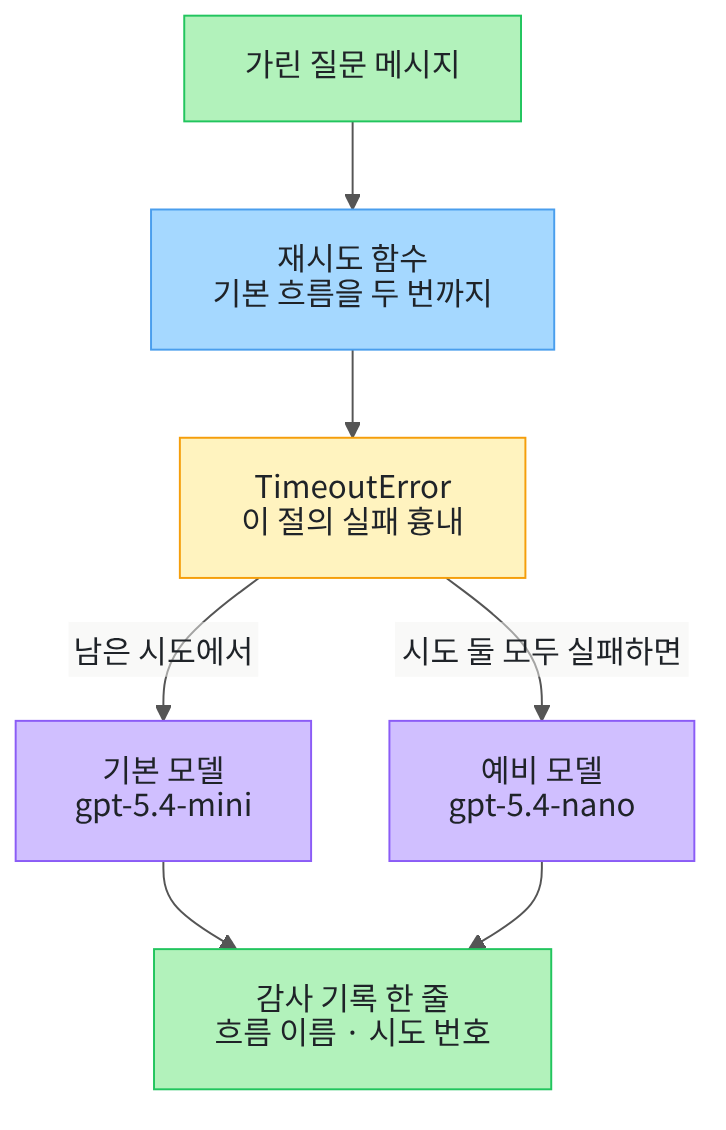

위에서 아래로 읽습니다. 파란 재시도 함수가 노란 실패 흉내를 받은 뒤 화살표가 둘로 나뉩니다.
왼쪽은 보라 기본 모델이, 오른쪽은 보라 예비 모델이 답하고, 두 쪽 모두 초록 감사 기록 한 줄로 모입니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 모듈과 앞 절 함수를 불러옵니다.
02절 함수 `mask_pii`·`find_raw_values`와 04절 함수 `make_budget`·`reserve`를 다시 씁니다.
모듈 `time`은 Ch 15 05절에서 `time.perf_counter()`를 쓸 때 불러온 모듈입니다.
모듈 `hashlib`은 Ch 7 08절과 Ch 15 03절에서 지문을 만들 때 쓴 모듈입니다.

앞에서 배운 함수는 `guardrails.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
네 함수 모두 앞 절에서 쓰던 인자 그대로입니다.

In [2]:
# 지문·JSON·파일 자리·잠시 쉬기에 쓸 모듈, 앞 절 함수 넷, 모델을 만들 이름을 불러옵니다
import hashlib
import json
import os
import time

from guardrails import find_raw_values, make_budget, mask_pii, reserve
from langchain.chat_models import init_chat_model

print("불러온 앞 절 함수:", "find_raw_values", "make_budget", "mask_pii", "reserve")

불러온 앞 절 함수: find_raw_values make_budget mask_pii reserve


**결과 읽기** — 출력 줄 `불러온 앞 절 함수: find_raw_values make_budget mask_pii reserve`로 함수 넷을 가져왔습니다.
네 함수는 02절과 04절 노트북에서 정의한 함수와 본문이 같습니다.

## 2. 키와 두 모델 준비

이 절은 모델 둘을 씁니다.
기본 모델 `gpt-5.4-mini`는 01~04절과 같은 모델입니다.
예비 모델 `gpt-5.4-nano`는 기본 모델이 끝내 답하지 못할 때만 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 답 문장이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

다음 셀은 예비 모델을 준비합니다.
예비 모델은 기본 모델이 끝내 답하지 못할 때 대신 부르는 모델입니다.
Ch 6 05절에서 대체 모델로 쓴 `gpt-5.4-nano`와 같은 이름입니다.
설정은 기본 모델과 같게 `temperature=0`과 `reasoning_effort="none"`을 줍니다.

In [5]:
# 기본 모델이 끝내 답하지 못할 때 부를 예비 모델을 준비합니다(Ch 6 05절의 대체 모델과 같은 이름)
backup_model = init_chat_model(
    "openai:gpt-5.4-nano",
    temperature=0,
    reasoning_effort="none",
)
print("예비 모델 이름:", backup_model.model_name)
print("temperature:", backup_model.temperature)

예비 모델 이름: gpt-5.4-nano
temperature: 0.0


**결과 읽기** — 출력 줄 `예비 모델 이름: gpt-5.4-nano`와 `temperature: 0.0`이 보이면 준비가 끝났습니다.
모델 객체를 만드는 줄은 요청을 보내지 않습니다.
예비 모델에 요청이 나가는 것은 5절 둘째 실행 한 번뿐입니다.

## 3. 자료와 이 절에서 정한 값

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01·02·04절과 같은 자리 찾기 셀입니다.

In [6]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch16-guardrails/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.
이 자리는 자료 파일을 읽을 때와 감사 기록 파일을 쓸 때 함께 씁니다.

다음 셀은 01·02·04절과 같은 자료 파일을 읽고 안내 문서 하나를 고릅니다.

In [7]:
# 자료 파일을 읽고 이 절의 검색 결과로 안내 문서 E01 하나만 고릅니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch16-guardrails/data"
with open(data_path + "/retrieved-documents.json", encoding="utf-8") as file:
    all_documents = json.loads(file.read())
retrieved = []
for document in all_documents:
    if document["doc_id"] == "E01":
        retrieved.append(document)
print("자료 파일의 문서 수:", len(all_documents))
print("이번 검색 결과의 문서 수:", len(retrieved))

자료 파일의 문서 수: 2
이번 검색 결과의 문서 수: 1


**결과 읽기** — 출력 줄 `자료 파일의 문서 수: 2`로 자료 파일의 문서는 둘입니다.
출력 줄 `이번 검색 결과의 문서 수: 1`로 이 절은 안내 문서 하나만 씁니다.

다음 셀은 01·02·04절과 같은 시스템 메시지 글과 검색 문서 한 줄을 적습니다.

In [8]:
# 01·02·04절과 같은 지킬 말과 검색 문서 한 줄입니다
system_text = "검색 문서에 있는 사실만 써서 한국어 한 문장으로 답하세요. 답 끝에 쓴 문서의 출처를 [문서ID p.쪽] 꼴로 적으세요."
document = retrieved[0]
document_line = "검색 문서 " + document["doc_id"] + " " + str(document["page"]) + "쪽: " + document["text"]
print("지킬 말:")
print(system_text)
print("검색 문서 한 줄:")
print(document_line)

지킬 말:
검색 문서에 있는 사실만 써서 한국어 한 문장으로 답하세요. 답 끝에 쓴 문서의 출처를 [문서ID p.쪽] 꼴로 적으세요.
검색 문서 한 줄:
검색 문서 E01 1쪽: 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관합니다. 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다.


**결과 읽기** — 라벨 줄 `지킬 말:` 아래 줄이 시스템 메시지로 보낼 글입니다.
라벨 줄 `검색 문서 한 줄:` 아래 줄이 질문과 함께 보낼 문서입니다.
두 글 모두 01·02·04절과 같습니다.
출력 라벨과 코드 주석의 「지킬 말」은 시스템 메시지 글을 부르는 이름입니다.
Ch 8 03절의 지킬 말(꼭 남아야 할 말 목록)과는 다른 뜻입니다.

다음 셀은 02절의 가짜 개인정보 둘을 넣은 질문을 만들고 가립니다.
두 값은 02절에서 지어낸 값이고 실제 사람의 정보가 아닙니다.
함수 `mask_pii`는 02절처럼 가린 글과 종류별 개수를 튜플 하나로 내놓습니다.

In [9]:
# 02절의 가짜 개인정보 둘을 넣은 질문을 만들고 02절 함수 mask_pii로 가립니다
fake_email = "test.user@example.com"
fake_phone = "010-0000-0000"
fake_values = [fake_email, fake_phone]
contact_line = "답은 " + fake_email + " 이나 " + fake_phone + " 으로 보내 주세요."
question = "도서관 휴관일은 언제인가요? " + contact_line
masked_question, pii_counts = mask_pii(question)
print("가린 질문:")
print(masked_question)
print("종류별 개수:", pii_counts)

가린 질문:
도서관 휴관일은 언제인가요? 답은 <EMAIL_MASKED> 이나 <PHONE_MASKED> 으로 보내 주세요.
종류별 개수: {'email': 1, 'phone': 1, 'rrn': 0, 'card': 0}


**결과 읽기** — 라벨 줄 `가린 질문:` 아래 줄에서 이메일과 전화번호가 표식으로 바뀌었습니다.
출력 줄 `종류별 개수: {'email': 1, 'phone': 1, 'rrn': 0, 'card': 0}`로 두 가지를 하나씩 가렸습니다.
원래 질문 `question`은 그대로 두고, 가린 글은 `masked_question`에 담았습니다.

다음 셀은 가린 질문으로 보낼 메시지를 만듭니다.
02절처럼 모델에게는 가린 질문만 보냅니다.

In [10]:
# 가린 질문으로 01·02·04절과 같은 모양의 메시지 두 개를 만듭니다(아직 보내지 않습니다)
messages = [
    {"role": "system", "content": system_text},
    {"role": "user", "content": "질문: " + masked_question + "\n" + document_line},
]
raw_in_messages = find_raw_values(messages[1]["content"], fake_values)
print("메시지 수:", len(messages))
print("보낼 메시지에 남은 원문 값 수:", len(raw_in_messages))

메시지 수: 2
보낼 메시지에 남은 원문 값 수: 0


**결과 읽기** — 출력 줄 `메시지 수: 2`로 01·02·04절과 같은 역할 딕셔너리 두 개입니다.
출력 줄 `보낼 메시지에 남은 원문 값 수: 0`으로 보낼 글에는 가짜 값 원문이 없습니다.
이 절의 모델 요청은 모두 이 메시지 `messages`를 보냅니다.

다음 셀은 재시도에 쓸 값 둘을 정합니다.
Ch 6 05절에서 본 재시도(retry)는 실패한 요청을 같은 설정으로 다시 보내는 일입니다.
이 절은 처음 부르는 쪽을 기본 흐름이라고 부릅니다.
기본 흐름을 몇 번까지 부를지가 시도 횟수이고, 첫 시도를 포함해 셉니다.

In [11]:
# 이 절에서 정한 값입니다: 기본 흐름을 부를 횟수와 시도 사이에 쉬는 초
attempts = 2
RETRY_WAIT_SECONDS = 0.05
print("기본 흐름 시도 횟수:", attempts)
print("시도 사이에 쉬는 초:", RETRY_WAIT_SECONDS)

기본 흐름 시도 횟수: 2
시도 사이에 쉬는 초: 0.05


**결과 읽기** — 출력 줄 `기본 흐름 시도 횟수: 2`로 기본 흐름은 두 번까지 부릅니다.
출력 줄 `시도 사이에 쉬는 초: 0.05`는 실패한 뒤 다음 시도 전에 쉬는 짧은 시간입니다.
이름 `RETRY_WAIT_SECONDS`는 02절처럼 바꾸지 않는 값이라 대문자로 적었습니다.

두 값은 흐름을 보여 주려고 정한 값입니다.
걸린 시간은 이 절에서 재지 않습니다.

다음 셀은 04절 예산에 쓸 값 셋을 정합니다.
04절 예약은 요청을 보내기 전에 적어서, 요청이 실패해도 예약은 남았습니다.
그래서 이 절은 다시 부를 때마다 먼저 예약합니다.
기본 흐름 두 번과 예비 흐름 한 번을 모두 셀 수 있게 호출 한도를 3으로 둡니다.

In [12]:
# 04절 예산에 쓸 값입니다: 기본 흐름 둘과 예비 흐름 하나를 모두 셀 수 있게 호출 한도를 3으로 둡니다
max_calls = 3
max_cost_usd = 0.01
estimated_cost = 0.002
print("호출 한도:", max_calls)
print("비용 상한(달러):", max_cost_usd)
print("요청 하나의 예상 비용(달러):", estimated_cost)

호출 한도: 3
비용 상한(달러): 0.01
요청 하나의 예상 비용(달러): 0.002


**결과 읽기** — 출력 줄 `호출 한도: 3`과 `비용 상한(달러): 0.01`이 한 번 실행의 예산입니다.
출력 줄 `요청 하나의 예상 비용(달러): 0.002`는 04절과 같은 정한 값입니다.
요금표로 센 값이 아니고 청구 금액도 아닙니다.

## 4. 실패 흉내와 예비 흐름

실제 모델 서비스의 시간 초과는 언제 날지 정할 수 없습니다.
그래서 이 절은 정해 둔 횟수만큼 `TimeoutError`를 내는 함수를 직접 만듭니다.
오류 `TimeoutError`는 파이썬에 들어 있는 시간 초과 오류입니다.
이 오류는 실제 서비스가 낸 것이 아니라 이 절에서 만든 실패 흉내입니다.

다음 셀은 기본 흐름 함수입니다.
첫 줄에서 04절 함수 `reserve`로 먼저 예약합니다.
딕셔너리 `failure_plan`의 칸 `fail_times`는 실패 흉내를 낼 횟수이고, 칸 `tries`는 부른 횟수입니다.
실패 흉내가 끝나면 실제 기본 모델을 부릅니다.

In [13]:
# 기본 흐름입니다: 먼저 예약하고, 정해 둔 횟수까지는 실패 흉내 TimeoutError를 내고 그 뒤에는 기본 모델을 부릅니다
def ask_primary():
    reserve(budget, estimated_cost)
    failure_plan["tries"] = failure_plan["tries"] + 1
    if failure_plan["tries"] <= failure_plan["fail_times"]:
        raise TimeoutError("이 절에서 만든 실패 흉내입니다.")
    return model.invoke(messages).text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ask_primary`는 부를 때마다 먼저 예약하고 칸 `tries`에 1을 더합니다.
부른 횟수가 `fail_times` 이하이면 `raise`로 `TimeoutError`를 내고 멈춥니다.
그보다 많이 부르면 기본 모델에게 메시지를 보내고 답 글을 내놓습니다.
이 함수는 인자가 없고, 노트북에서 만든 이름 `budget`·`failure_plan`·`messages`를 씁니다.

다음 셀은 실패 흉내를 한 번으로 정하고 기본 흐름을 한 번만 불러 봅니다.
예산 `budget`도 04절 함수 `make_budget`으로 새로 만듭니다.
오류는 03절처럼 `try/except`로 받습니다.

In [14]:
# 실패 흉내를 한 번으로 정하고 기본 흐름을 한 번만 불러 봅니다(실패 흉내에 걸려 모델은 부르지 않습니다)
failure_plan = {"fail_times": 1, "tries": 0}
budget = make_budget(max_calls, max_cost_usd)
try:
    ask_primary()
except TimeoutError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:", error)
print("기본 흐름 시도 수:", failure_plan["tries"])
print("예약한 호출 수:", budget["calls"])

오류 종류: TimeoutError
오류 메시지: 이 절에서 만든 실패 흉내입니다.
기본 흐름 시도 수: 1
예약한 호출 수: 1


**결과 읽기** — 출력 줄 `오류 종류: TimeoutError`와 `오류 메시지: 이 절에서 만든 실패 흉내입니다.`가 받은 오류입니다.
출력 줄 `기본 흐름 시도 수: 1`로 기본 흐름을 한 번 불렀습니다.
출력 줄 `예약한 호출 수: 1`로 실패한 시도도 예약은 남았습니다.

실제 시간 초과는 요청이 이미 나간 뒤에 날 수도 있습니다.
그래서 실패한 시도도 호출 한 번으로 셉니다.
실제 시간 초과가 언제 나는지는 이번에 확인하지 않았습니다.
이 실패 흉내는 모델을 부르기 전에 나서 이 셀에서 모델 요청은 없었습니다.

다음 셀은 예비 흐름 함수입니다.
Ch 6 05절에서 본 폴백(fallback)은 기본 흐름이 끝내 실패하면 미리 정한 다른 흐름으로 넘기는 일입니다.
이 절은 그 다른 흐름을 예비 흐름, 예비 흐름이 낸 답을 예비 답이라고 부릅니다.
예비 모델을 부르는 것도 모델 요청이라 먼저 예약합니다.

In [15]:
# 예비 흐름입니다: 먼저 예약하고 예비 모델에게 같은 메시지를 보냅니다(부르면 모델 요청 1번)
def ask_backup():
    reserve(budget, estimated_cost)
    return backup_model.invoke(messages).text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ask_backup`은 먼저 예약한 뒤 예비 모델 `backup_model`에게 같은 메시지를 보냅니다.
이 함수에는 실패 흉내를 넣지 않았습니다.
그래서 예약이 되면 예비 모델에 요청이 한 번 나갑니다.

## 5. 재시도 함수

다음 셀은 이 절의 중심 함수입니다.
기본 흐름을 시도 횟수까지 부르고, 답을 받으면 그 자리에서 내놓습니다.
시도에서 `TimeoutError`가 나면 다음 시도로 넘어갑니다.
모든 시도가 `TimeoutError`로 끝나면 예비 흐름을 부릅니다.
마지막 시도가 아니면 다음 시도 전에 인자 `wait`로 받은 함수로 잠시 쉽니다.

In [16]:
# 시간 초과면 정한 횟수까지 다시 부르고, 끝내 안 되면 예비 흐름의 답을 냅니다
def retry_with_fallback(primary, fallback, attempts, wait):
    for index in range(1, attempts + 1):
        try:
            return primary(), "primary", index
        except TimeoutError:
            if index < attempts:
                wait(RETRY_WAIT_SECONDS)
    return fallback(), "fallback", attempts + 1

**결과 읽기** — 정의 셀이라 출력이 없습니다.
블록 `try` 안의 `return`은 기본 흐름이 답하면 값 셋을 튜플 하나로 내놓고 함수를 끝냅니다.
값 셋은 답 글, 받은 흐름 이름, 답을 받은 시도 번호입니다.
흐름 이름 `"primary"`는 기본 흐름, `"fallback"`은 예비 흐름에서 받은 답이라는 표시입니다.
예비 흐름의 시도 번호는 기본 흐름 시도 횟수에 1을 더한 값입니다.

블록 `except TimeoutError`는 이 오류 이름만 받습니다.
예약이 막혀 난 `ValueError` 같은 다른 오류는 받지 않고 그대로 밖으로 나갑니다.
인자 `attempts`는 함수 안의 이름이라 3절에서 정한 바깥 이름 `attempts`와 따로입니다.

다음 셀은 실패 흉내를 한 번으로 정하고 재시도 함수를 부릅니다.
함수 `time.sleep(초)`는 정한 초만큼 쉬었다가 다음 줄로 갑니다.
03절처럼 함수를 괄호 없이 넘기므로, 재시도 함수 안에서 쉴 때만 불립니다.
02절 튜플 풀기처럼 왼쪽에 이름 셋을 적어 값 셋을 차례로 받습니다.
첫 시도는 실패 흉내에 걸리고, 두 번째 시도에서 기본 모델에 요청이 나갈 것입니다.

In [17]:
# 실패 흉내 한 번으로 정하고 새 예산으로 재시도 함수를 부릅니다(두 번째 시도에서 모델 요청 1번)
failure_plan = {"fail_times": 1, "tries": 0}
budget = make_budget(max_calls, max_cost_usd)
answer_one, route_one, attempt_one = retry_with_fallback(ask_primary, ask_backup, attempts, time.sleep)
detail_one = {"route": route_one, "attempt": attempt_one, "reserved_calls": budget["calls"]}
print("받은 흐름:", route_one)
print("답을 받은 시도 번호:", attempt_one)
print("예약한 호출 수:", budget["calls"])
print("받은 답:")
print(answer_one)

받은 흐름: primary
답을 받은 시도 번호: 2
예약한 호출 수: 2
받은 답:
미르시립도서관은 매주 월요일과 법정 공휴일에 휴관하며, 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다. [E01 p.1]


**결과 읽기** — 출력 줄 `받은 흐름: primary`로 기본 흐름에서 답을 받았습니다.
출력 줄 `답을 받은 시도 번호: 2`로 첫 시도는 실패 흉내에 걸렸고 두 번째 시도에서 답했습니다.
출력 줄 `예약한 호출 수: 2`는 실패한 첫 시도와 답한 두 번째 시도를 함께 센 값입니다.
모델 요청은 두 번째 시도의 한 번뿐입니다.

라벨 줄 `받은 답:` 아래가 기본 모델 `gpt-5.4-mini`가 쓴 답입니다.
이 답은 모델이 쓴 글이라 여러분 실행에서는 문장이 다를 수 있습니다.
이번 실행에서는 답 끝에 출처 표시 `[E01 p.1]`이 붙었습니다.
교재 출력을 만들며 새 커널로 두 번 실행했을 때 답 문장은 두 번 모두 같았습니다.

다음 셀은 실패 흉내를 두 번으로 정하고 같은 재시도 함수를 부릅니다.
시도 횟수가 2라서 기본 흐름 두 번이 모두 실패 흉내에 걸릴 것입니다.
그러면 예비 흐름이 불려 예비 모델에 요청이 한 번 나갈 것입니다.

In [18]:
# 실패 흉내 두 번으로 정하고 새 예산으로 같은 함수를 부릅니다(예비 흐름에서 모델 요청 1번)
failure_plan = {"fail_times": 2, "tries": 0}
budget = make_budget(max_calls, max_cost_usd)
answer_two, route_two, attempt_two = retry_with_fallback(ask_primary, ask_backup, attempts, time.sleep)
detail_two = {"route": route_two, "attempt": attempt_two, "reserved_calls": budget["calls"]}
print("받은 흐름:", route_two)
print("답을 받은 시도 번호:", attempt_two)
print("예약한 호출 수:", budget["calls"])
print("받은 답:")
print(answer_two)

받은 흐름: fallback
답을 받은 시도 번호: 3
예약한 호출 수: 3
받은 답:
미르시립도서관은 매주 월요일과 법정 공휴일에 휴관하며, 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다. [E01 1쪽]


**결과 읽기** — 출력 줄 `받은 흐름: fallback`으로 이번에는 예비 흐름에서 답을 받았습니다.
출력 줄 `답을 받은 시도 번호: 3`은 기본 흐름 두 번 뒤의 세 번째 부르기라는 뜻입니다.
출력 줄 `예약한 호출 수: 3`은 실패한 두 시도와 예비 흐름 한 번을 함께 센 값입니다.
모델 요청은 예비 모델에 보낸 한 번뿐입니다.

라벨 줄 `받은 답:` 아래가 예비 모델 `gpt-5.4-nano`가 쓴 예비 답입니다.
이 답도 모델이 쓴 글이라 여러분 실행에서는 문장이 다를 수 있습니다.

이번 실행에서는 예비 답 끝의 출처 표시가 `[E01 1쪽]` 꼴이라 시스템 메시지가 정한 꼴과 달랐습니다.
교재 출력을 만들며 새 커널로 두 번 실행했을 때도 두 번 모두 같은 답이었습니다.
예비 모델의 답은 기본 모델의 답과 모양이 다를 수 있습니다.
이 절은 예비 답에 01절 출력 검사를 걸지 않았습니다.

두 실행은 실패 흉내 횟수 하나만 달랐습니다.
실패 흉내가 시도 횟수보다 적으면 기본 흐름이, 시도 횟수만큼이면 예비 흐름이 답했습니다.

## 6. 감사 기록 함수

제목의 감사 로그(audit log)를 이 절에서는 감사 기록이라고 부릅니다.
감사 기록은 나중에 실행을 다시 살펴보려고 사건마다 한 줄씩 남기는 기록입니다.
02절에서는 기록 한 줄을 글로만 만들었고 파일에 쓰지 않았습니다.
이 절은 5절 두 실행의 결과를 파일에 한 줄씩 남깁니다.

기록 한 줄에는 질문 원문 대신 가린 질문과 지문을 적습니다.
지문은 글을 정해진 규칙으로 섞어 만든 짧은 글이고, 같은 글은 늘 같은 지문이 됩니다.
소금값(salt)은 지문을 만들기 전에 글 앞에 붙이는 정한 글입니다.
소금값이 다르면 같은 질문도 지문이 달라집니다.

다음 셀은 소금값을 붙인 글로 지문을 만드는 함수입니다.
Ch 15 03절처럼 글을 바이트로 바꾸고, `hashlib.sha256`에 넣고, `hexdigest()`로 글자를 꺼냅니다.

In [19]:
# 소금값을 앞에 붙인 글로 지문을 만들고 앞 12글자만 씁니다
def fingerprint_of(salt, text):
    salted_text = salt + text
    salted_bytes = salted_text.encode("utf-8")
    salted_hash = hashlib.sha256(salted_bytes)
    return salted_hash.hexdigest()[:12]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `fingerprint_of`는 소금값과 글을 이어 붙인 뒤 지문을 만듭니다.
지문은 64글자인데, 기록 한 줄이 짧게 보이도록 앞 12글자만 내놓습니다.

다음 셀은 이 절의 소금값을 정하고 가린 질문의 지문을 만들어 봅니다.
같은 소금값으로 두 번 만든 지문과, 소금값만 바꾼 지문을 견줍니다.
지문 값 자체는 인용하지 않고 같은지만 봅니다.

In [20]:
# 이 절의 소금값을 정하고, 가린 질문의 지문을 두 번 만든 뒤 소금값만 바꾼 지문과 견줍니다
session_salt = "ch16-session"
other_salt = "other-session"
first_print = fingerprint_of(session_salt, masked_question)
second_print = fingerprint_of(session_salt, masked_question)
other_print = fingerprint_of(other_salt, masked_question)
print("지문 글자 수:", len(first_print))
print("같은 글·같은 소금값의 두 지문이 같은가:", first_print == second_print)
print("소금값만 바꾼 지문과 같은가:", first_print == other_print)

지문 글자 수: 12
같은 글·같은 소금값의 두 지문이 같은가: True
소금값만 바꾼 지문과 같은가: False


**결과 읽기** — 출력 줄 `지문 글자 수: 12`로 지문은 12글자입니다.
출력 줄 `같은 글·같은 소금값의 두 지문이 같은가: True`로 같은 글은 같은 지문이 됩니다.
출력 줄 `소금값만 바꾼 지문과 같은가: False`로 소금값을 바꾸면 지문도 바뀝니다.
이 절의 소금값은 이름 `session_salt`에 담은 글입니다.

다음 셀은 기록에 남길 값을 가리는 함수입니다.
기록 한 줄의 칸 `detail`에는 목록이나 딕셔너리가 안쪽까지 겹쳐 들어올 수 있습니다.
그래서 값을 통째로 JSON 글로 바꾼 뒤 02절 `mask_pii`로 가리고, 다시 값으로 읽습니다.
함수 `json.dumps`는 값을 JSON 글로 바꾸고, 함수 `json.loads`는 JSON 글을 값으로 바꿉니다.

In [21]:
# 기록에 남길 값을 JSON 글로 바꿔 통째로 가린 뒤 다시 값으로 읽습니다
def safe_detail(detail):
    detail_text = json.dumps(detail, ensure_ascii=False)
    masked_text = mask_pii(detail_text)[0]
    return json.loads(masked_text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `safe_detail`은 안쪽의 목록과 딕셔너리까지 글 하나로 펴서 한 번에 가립니다.
값이 얼마나 겹쳐 들어 있어도 같은 세 줄로 처리합니다.
가린 글을 다시 읽으므로 내놓는 값은 받은 값과 같은 모양입니다.

다음 셀은 목록 안에 가짜 전화번호가 든 값을 가려 봅니다.

In [22]:
# 목록 안에 가짜 전화번호가 든 값을 가려 봅니다
nested_detail = {"route": "fallback", "notes": ["연락처 " + fake_phone]}
safe_nested = safe_detail(nested_detail)
print("가리기 전:", nested_detail)
print("가린 뒤:", safe_nested)

가리기 전: {'route': 'fallback', 'notes': ['연락처 010-0000-0000']}
가린 뒤: {'route': 'fallback', 'notes': ['연락처 <PHONE_MASKED>']}


**결과 읽기** — 출력 줄 `가린 뒤: {'route': 'fallback', 'notes': ['연락처 <PHONE_MASKED>']}`에서 목록 안의 전화번호도 표식으로 바뀌었습니다.
칸 `route`의 글은 개인정보가 아니라서 그대로 남았습니다.
딕셔너리와 목록 모양도 가리기 전과 같습니다.

다음 셀은 감사 기록 딕셔너리를 만드는 함수입니다.
04절 예산처럼 칸 몇 개를 담은 딕셔너리 하나로 기록을 다룹니다.
칸 `path`는 파일 자리, 칸 `salt`는 소금값, 칸 `rows`는 기록 한 줄들을 담는 목록입니다.

In [23]:
# 감사 기록 파일 자리와 소금값, 빈 기록 목록을 담은 딕셔너리를 만듭니다
def make_audit_log(path, session_salt):
    return {"path": path, "salt": session_salt, "rows": []}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_audit_log`는 파일을 만들지 않고 딕셔너리만 내놓습니다.
파일은 기록 한 줄을 더할 때 씁니다.

다음 셀은 기록 목록 전체를 파일에 쓰는 함수입니다.
Ch 15 08절처럼 기록 한 줄을 `json.dumps`로 JSON 글 한 줄로 바꿉니다.
파일은 `with open(…, "w", encoding="utf-8")`로 엽니다.
여는 방식 `"w"`는 있던 내용을 지우고 새로 씁니다.

In [24]:
# 기록 목록 전체를 JSON 글 한 줄씩으로 바꿔 파일에 덮어씁니다
def write_audit_rows(log):
    lines = []
    for row in log["rows"]:
        lines.append(json.dumps(row, ensure_ascii=False))
    with open(log["path"], "w", encoding="utf-8") as file:
        file.write("\n".join(lines) + "\n")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `write_audit_rows`는 목록 `lines`를 줄바꿈 `"\n"`으로 이어 붙이고 끝에도 줄바꿈을 붙입니다.
부를 때마다 기록 목록 전체를 처음부터 다시 씁니다.
그래서 노트북을 다시 실행해도 파일에 줄이 쌓이지 않습니다.

다음 셀은 기록 한 줄을 더하는 함수입니다.
받은 질문은 원문 그대로 받아도 되고, 함수 안에서 먼저 가립니다.
지문은 가린 질문으로 만들어서 원문이 지문 안에도 들어가지 않습니다.
칸 `detail`은 앞에서 만든 `safe_detail`로 가립니다.

In [25]:
# 질문을 가리고 지문을 붙여 감사 기록 한 줄을 더한 뒤 파일 전체를 다시 씁니다
def record_event(log, event, query, detail):
    masked_query = mask_pii(query)[0]
    fingerprint = fingerprint_of(log["salt"], masked_query)
    row = {"event": event, "query_hash": fingerprint,
           "query_masked": masked_query, "detail": safe_detail(detail)}
    log["rows"].append(row)
    write_audit_rows(log)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `record_event`는 기록 한 줄을 칸 넷의 딕셔너리로 만듭니다.
칸은 사건 이름 `event`, 지문 `query_hash`, 가린 질문 `query_masked`, 가린 값 `detail`입니다.
한 줄을 목록에 더한 뒤 파일 전체를 다시 쓰고, 더한 한 줄을 내놓습니다.

모델 답 문장은 이 칸에 넣지 않습니다.
답 문장은 실행마다 달라질 수 있고, 답에도 개인정보가 섞일 수 있기 때문입니다.
기록에는 코드가 정한 값만 남겨 다시 실행해도 같은 파일이 되게 합니다.

## 7. 두 실행을 감사 기록 파일에 남기기

다음 셀은 실습 폴더의 `runs` 폴더에 파일 자리를 정합니다.
Ch 15 08절처럼 폴더가 없으면 `os.makedirs`로 먼저 만듭니다.
그다음 5절 두 실행의 결과를 사건 이름 `answer`로 한 줄씩 남깁니다.
질문은 가리기 전 원문 `question`을 그대로 넘깁니다.

In [26]:
# runs 폴더에 감사 기록 파일 자리를 정하고, 5절 두 실행의 결과를 한 줄씩 남깁니다
runs_path = root_path + "/labs/part4/ch16-guardrails/runs"
if not os.path.exists(runs_path):
    os.makedirs(runs_path)
audit_log = make_audit_log(runs_path + "/05-audit.jsonl", session_salt)
record_event(audit_log, "answer", question, detail_one)
record_event(audit_log, "answer", question, detail_two)
print("감사 기록 줄 수:", len(audit_log["rows"]))
first_keys = list(audit_log["rows"][0].keys())
print("첫 줄의 칸:", first_keys)

감사 기록 줄 수: 2
첫 줄의 칸: ['event', 'query_hash', 'query_masked', 'detail']


**결과 읽기** — 출력 줄 `감사 기록 줄 수: 2`로 두 실행이 한 줄씩 남았습니다.
출력 줄 `첫 줄의 칸: ['event', 'query_hash', 'query_masked', 'detail']`이 기록 한 줄의 칸 넷입니다.
칸 `detail`에는 5절에서 만든 흐름 이름·시도 번호·예약한 호출 수가 들어 있습니다.

다음 셀은 방금 쓴 파일을 다시 읽습니다.
Ch 15 08절의 `str.count`로 줄바꿈 수를 세어 줄 수를 봅니다.
02절 함수 `find_raw_values`로 가짜 값 원문이 파일에 남았는지도 봅니다.

In [27]:
# 파일을 다시 읽어 줄 수를 세고, 가짜 개인정보 원문이 남았는지 봅니다
with open(audit_log["path"], encoding="utf-8") as file:
    audit_text = file.read()
raw_in_file = find_raw_values(audit_text, fake_values)
print("파일의 줄 수:", audit_text.count("\n"))
print("파일에 남은 원문 값:", raw_in_file)
print("파일 내용:")
print(audit_text)

파일의 줄 수: 2
파일에 남은 원문 값: []
파일 내용:
{"event": "answer", "query_hash": "cf4ab66b4243", "query_masked": "도서관 휴관일은 언제인가요? 답은 <EMAIL_MASKED> 이나 <PHONE_MASKED> 으로 보내 주세요.", "detail": {"route": "primary", "attempt": 2, "reserved_calls": 2}}
{"event": "answer", "query_hash": "cf4ab66b4243", "query_masked": "도서관 휴관일은 언제인가요? 답은 <EMAIL_MASKED> 이나 <PHONE_MASKED> 으로 보내 주세요.", "detail": {"route": "fallback", "attempt": 3, "reserved_calls": 3}}



**결과 읽기** — 출력 줄 `파일의 줄 수: 2`로 파일에도 두 줄이 있습니다.
출력 줄 `파일에 남은 원문 값: []`으로 가짜 이메일과 전화번호 원문은 파일에 없습니다.
라벨 줄 `파일 내용:` 아래 두 줄이 파일에 쓴 JSON 글입니다.

두 줄의 칸 `query_hash`는 같습니다.
같은 질문을 가려 같은 소금값으로 지문을 만들었기 때문입니다.
칸 `detail`을 보면 어느 실행이 어느 흐름에서 답을 받았는지 알 수 있습니다.

## 8. 손으로 정한 값으로 확인하기

다음 셀은 같은 기록 목록으로 파일을 한 번 더 씁니다.
여는 방식 `"w"`는 있던 내용을 지우므로 줄이 늘지 않아야 합니다.
기록 칸은 모두 코드가 정한 값이라 결과를 `assert`로 확인할 수 있습니다.

In [28]:
# 같은 기록 목록으로 파일을 한 번 더 씁니다(코드가 정한 값이라 assert로 봅니다)
write_audit_rows(audit_log)
with open(audit_log["path"], encoding="utf-8") as file:
    rewritten_text = file.read()
print("다시 쓴 뒤 파일의 줄 수:", rewritten_text.count("\n"))
print("처음 읽은 내용과 같은가:", rewritten_text == audit_text)
assert rewritten_text == audit_text
assert find_raw_values(rewritten_text, fake_values) == []

다시 쓴 뒤 파일의 줄 수: 2
처음 읽은 내용과 같은가: True


**결과 읽기** — 출력 줄 `다시 쓴 뒤 파일의 줄 수: 2`로 줄이 늘지 않았습니다.
출력 줄 `처음 읽은 내용과 같은가: True`로 파일 내용도 글자까지 같습니다.
마지막 두 줄의 `assert`도 통과했습니다.

## 9. 값 바꿔 보기 · 호출 한도 2

바꿀 값은 호출 한도 하나입니다.
3 대신 2로 새 예산을 만들고, 실패 흉내 두 번인 5절 둘째 실행을 다시 부릅니다.
시도 횟수 2와 요청 하나의 예상 비용 0.002는 그대로입니다.

실행 전에 예상해 봅니다.
기본 흐름 두 번의 예약으로 호출 한도 2를 다 씁니다.
예비 흐름의 예약은 `호출 한도를 넘습니다.`로 막히고, 예비 모델은 부르지 않을 것입니다.
재시도 함수는 `ValueError`를 받지 않으므로 그 오류는 셀의 `except ValueError`가 받습니다.
받은 까닭은 사건 이름 `stopped`로 감사 기록에 한 줄 남깁니다.

In [29]:
# 바꿀 값은 호출 한도 하나입니다: 3 대신 2로 두고 실패 흉내 두 번인 흐름을 다시 부릅니다
small_call_limit = 2
failure_plan = {"fail_times": 2, "tries": 0}
budget = make_budget(small_call_limit, max_cost_usd)
try:
    retry_with_fallback(ask_primary, ask_backup, attempts, time.sleep)
except ValueError as error:
    stop_detail = {"reason": str(error), "reserved_calls": budget["calls"]}
    record_event(audit_log, "stopped", question, stop_detail)
print("마지막 기록 칸:", audit_log["rows"][-1]["detail"])
print("감사 기록 줄 수:", len(audit_log["rows"]))

마지막 기록 칸: {'reason': '호출 한도를 넘습니다.', 'reserved_calls': 2}
감사 기록 줄 수: 3


**결과 읽기** — 출력 줄 `마지막 기록 칸: {'reason': '호출 한도를 넘습니다.', 'reserved_calls': 2}`가 새로 남긴 한 줄입니다.
예상대로 예비 흐름의 예약이 호출 한도에서 막혔습니다.
출력 줄 `감사 기록 줄 수: 3`으로 파일은 이제 세 줄입니다.

이 셀에서 모델 요청은 없었습니다.
기본 흐름 두 번은 실패 흉내에서, 예비 흐름은 예약에서 멈췄기 때문입니다.
5절 둘째 실행은 호출 한도가 3이라 `받은 흐름: fallback`이었습니다.

## 정리

1. 정해 둔 횟수만큼 `TimeoutError`를 내는 실패 흉내로 다시 부르기와 예비 흐름을 실행했습니다.
2. 실패 흉내가 한 번이면 두 번째 시도에서 기본 모델이, 두 번이면 예비 모델이 답했습니다.
3. 가린 질문·지문·흐름 이름·시도 번호만 감사 기록 파일에 남겼고, 다시 써도 내용이 같았습니다.

06절에서는 검색 문서 속 지시문이 답에 끼어드는지 보고, 앞 절 방어를 한 흐름으로 잇습니다.